<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/13_RNN_LSTM_GRU_PLN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">RNN, LSTM y GRU aplicadas a PLN</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Redes neuronales recurrentes</span>](#redes-neuronales-recurrentes)
- [<span style="color: #005C99;">El gradiente que se desvanece</span>](#el-gradiente-que-se-desvanece)
- [<span style="color: #005C99;">LSTM</span>](#lstm)
- [<span style="color: #005C99;">GRU</span>](#gru)
- [<span style="color: #005C99;">Clasificación de sentimiento con modelos secuenciales</span>](#clasificacion-de-sentimiento-con-modelos-secuenciales)
- [<span style="color: #005C99;">¿Entienden las negaciones?</span>](#entienden-las-negaciones)
- [<span style="color: #005C99;">Generación de texto carácter a carácter</span>](#generacion-de-texto-caracter-a-caracter)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib tensorflow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

Los clasificadores del cuaderno 11 promediaban los embeddings de una reseña: una bolsa de palabras densa. Pero en el lenguaje **el orden importa**:

- *"no es bueno, es excelente"* frente a *"no es excelente, es bueno"*.
- *"el perro muerde al hombre"* frente a *"el hombre muerde al perro"*.

Los N-gramas (módulo 2) capturaban el orden en una ventana corta y fija. Las **redes neuronales recurrentes** (RNN) procesan la secuencia palabra por palabra manteniendo un **estado oculto** que resume todo lo visto hasta el momento, sin límite fijo de contexto.

En el curso de Aprendizaje Profundo se estudiaron las RNN, LSTM y GRU aplicadas a series de tiempo. Aquí repasamos brevemente su funcionamiento y nos concentramos en sus particularidades con **texto**: embeddings como entrada, relleno y máscaras, redes bidireccionales y generación de lenguaje.

<a id="redes-neuronales-recurrentes"></a>
<h2 style="color: #007ACC;">Redes neuronales recurrentes</h2>

Una RNN aplica **la misma** transformación en cada paso $t$, combinando la entrada actual $\mathbf{x}_t$ (el embedding de la palabra $t$) con el estado anterior $\mathbf{h}_{t-1}$:

$$\mathbf{h}_t = \tanh\left( W_{xh}\, \mathbf{x}_t + W_{hh}\, \mathbf{h}_{t-1} + \mathbf{b}_h \right)$$

```text
       y            (para clasificación se usa solo el último estado h_T)
       ▲
h0 → [RNN] → h1 → [RNN] → h2 → [RNN] → h3
       ▲             ▲             ▲
       x1            x2            x3
      "no"         "está"         "mal"
```

- Los pesos $W_{xh}$, $W_{hh}$ y $\mathbf{b}_h$ se **comparten** entre todos los pasos: la red puede procesar secuencias de cualquier longitud con un número fijo de parámetros.
- El estado $\mathbf{h}_t$ funciona como una **memoria** de la parte de la oración ya leída.

Implementemos el paso hacia adelante en NumPy y comprobemos que coincide con `SimpleRNN` de Keras:

In [3]:
rng = np.random.default_rng(SEED)
d_entrada, d_oculto, T = 4, 3, 5
x = rng.normal(size=(T, d_entrada)).astype("float32")

rnn = layers.SimpleRNN(d_oculto, return_sequences=True)
salida_keras = rnn(x[None])[0].numpy()
W_xh, W_hh, b = rnn.get_weights()  # Keras guarda W_xh con forma (d_entrada, d_oculto)

h = np.zeros(d_oculto)
estados = []
for t in range(T):
    h = np.tanh(x[t] @ W_xh + h @ W_hh + b)
    estados.append(h)

print("¿Coinciden NumPy y Keras?", np.allclose(np.array(estados), salida_keras, atol=1e-5))
print("Estados ocultos h_1 ... h_5:")
print(np.array(estados).round(3))

¿Coinciden NumPy y Keras? True
Estados ocultos h_1 ... h_5:
[[-0.242 -0.785  0.309]
 [-0.982 -0.625 -0.755]
 [-0.885 -0.119 -0.543]
 [ 0.422  0.96  -0.884]
 [ 0.067 -0.251  0.905]]


<a id="el-gradiente-que-se-desvanece"></a>
<h2 style="color: #007ACC;">El gradiente que se desvanece</h2>

Para entrenar una RNN se aplica **retropropagación a través del tiempo** (BPTT): se "desenrolla" la red y el gradiente del error en el paso $T$ con respecto al estado en el paso $k$ es un producto de jacobianos:

$$\frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_k} = \prod_{t=k+1}^{T} \frac{\partial \mathbf{h}_t}{\partial \mathbf{h}_{t-1}} = \prod_{t=k+1}^{T} \text{diag}\left(1 - \mathbf{h}_t^2\right) W_{hh}$$

Si las normas de estos factores son menores que 1, el producto **decae exponencialmente** con la distancia $T - k$ (gradiente que se desvanece); si son mayores, **explota**. En la práctica, una RNN simple apenas aprende dependencias de más de 10–20 pasos: en *"El libro que me recomendó mi profesora de la universidad el año pasado **es** excelente"*, la red tiene dificultades para relacionar *es* con *libro*.

Midamos la norma de $\partial \mathbf{h}_T / \partial \mathbf{h}_k$ en una RNN con pesos aleatorios:

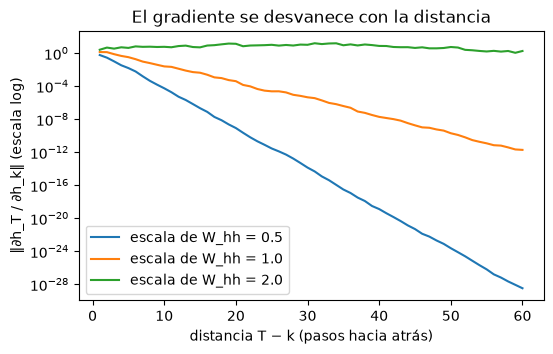

In [4]:
def norma_gradiente(escala, T=60, d=32, rng=None):
    rng = rng or np.random.default_rng(SEED)
    W = rng.normal(scale=escala / np.sqrt(d), size=(d, d))
    h, jacobianos = np.zeros(d), []
    for _ in range(T):
        h = np.tanh(W @ h + rng.normal(size=d))
        jacobianos.append(np.diag(1 - h ** 2) @ W)
    normas, J = [], np.eye(d)
    for jac in reversed(jacobianos):  # acumulamos desde el final hacia atrás
        J = J @ jac
        normas.append(np.linalg.norm(J, 2))
    return normas


plt.figure(figsize=(6, 3.5))
for escala in [0.5, 1.0, 2.0]:
    plt.semilogy(range(1, 61), norma_gradiente(escala), label=f"escala de W_hh = {escala}")
plt.xlabel("distancia T − k (pasos hacia atrás)")
plt.ylabel("‖∂h_T / ∂h_k‖ (escala log)")
plt.title("El gradiente se desvanece con la distancia")
plt.legend()
plt.show()

En los tres casos la norma cae varios órdenes de magnitud en pocas decenas de pasos: la información de las primeras palabras casi no influye en el aprendizaje. Las arquitecturas **con compuertas** (LSTM y GRU) resuelven este problema. La explosión del gradiente, por su parte, se controla recortando su norma (*gradient clipping*).

<a id="lstm"></a>
<h2 style="color: #007ACC;">LSTM</h2>

La **LSTM** (*Long Short-Term Memory*, Hochreiter & Schmidhuber, 1997) añade una **celda de memoria** $\mathbf{c}_t$ que se actualiza de forma **aditiva**, controlada por tres compuertas con valores entre 0 y 1:

$$\begin{aligned}
\mathbf{f}_t &= \sigma(W_f [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_f) && \text{olvido: qué borrar de la memoria} \\
\mathbf{i}_t &= \sigma(W_i [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_i) && \text{entrada: qué escribir} \\
\tilde{\mathbf{c}}_t &= \tanh(W_c [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c) && \text{contenido candidato} \\
\mathbf{c}_t &= \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t && \text{actualización aditiva de la memoria} \\
\mathbf{o}_t &= \sigma(W_o [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_o) && \text{salida: qué mostrar} \\
\mathbf{h}_t &= \mathbf{o}_t \odot \tanh(\mathbf{c}_t)
\end{aligned}$$

Como $\partial \mathbf{c}_t / \partial \mathbf{c}_{t-1} = \text{diag}(\mathbf{f}_t)$, si la compuerta de olvido está cerca de 1 la información (y el gradiente) puede viajar muchos pasos sin desvanecerse. En texto, una LSTM puede "recordar" que vio un *no* varias palabras atrás.

<a id="gru"></a>
<h2 style="color: #007ACC;">GRU</h2>

La **GRU** (*Gated Recurrent Unit*, Cho et al., 2014) simplifica la LSTM: fusiona la celda y el estado oculto y usa solo dos compuertas:

$$\begin{aligned}
\mathbf{z}_t &= \sigma(W_z [\mathbf{h}_{t-1}, \mathbf{x}_t]) && \text{actualización} \\
\mathbf{r}_t &= \sigma(W_r [\mathbf{h}_{t-1}, \mathbf{x}_t]) && \text{reinicio} \\
\tilde{\mathbf{h}}_t &= \tanh(W [\mathbf{r}_t \odot \mathbf{h}_{t-1}, \mathbf{x}_t]) \\
\mathbf{h}_t &= (1 - \mathbf{z}_t) \odot \mathbf{h}_{t-1} + \mathbf{z}_t \odot \tilde{\mathbf{h}}_t
\end{aligned}$$

Tiene menos parámetros y suele rendir de forma muy parecida a la LSTM. Comparemos el número de parámetros para la misma entrada y el mismo tamaño de estado:

In [5]:
d_x, unidades = 64, 64
parametros = {}
for nombre, capa in [("SimpleRNN", layers.SimpleRNN), ("GRU", layers.GRU), ("LSTM", layers.LSTM)]:
    modelo = keras.Sequential([keras.Input(shape=(None, d_x)), capa(unidades)])
    parametros[nombre] = modelo.count_params()
pd.Series(parametros, name=f"parámetros (entrada {d_x}, estado {unidades})").to_frame()

,"parámetros (entrada 64, estado 64)"
SimpleRNN,8256
GRU,24960
LSTM,33024


La LSTM tiene cuatro matrices (tres compuertas y el candidato), la GRU tres y la RNN simple una; por eso las proporciones son aproximadamente 4 : 3 : 1.

<a id="clasificacion-de-sentimiento-con-modelos-secuenciales"></a>
<h2 style="color: #007ACC;">Clasificación de sentimiento con modelos secuenciales</h2>

Retomamos la tarea del cuaderno 11: sentimiento binario en reseñas de Amazon en español, con los mismos datos y la misma vectorización.

In [6]:
from datasets import load_dataset

# Reseñas de Amazon en español: 200 000 de entrenamiento, 5 000 de validación y 5 000 de prueba.
# La etiqueta va de 0 a 4 (de 1 a 5 estrellas).
resenas = load_dataset("SetFit/amazon_reviews_multi_es")


def a_binario(split, n=None):
    """Reseñas negativas (1-2 estrellas) -> 0, positivas (4-5 estrellas) -> 1; se descartan las de 3."""
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=SEED)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_train_txt, y_train = a_binario("train", n=60_000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivas en entrenamiento: {y_train.mean():.2f}")
for texto, etiqueta in zip(X_train_txt[:3], y_train[:3]):
    print(f"[{'positiva' if etiqueta else 'negativa'}] {texto}")

Entrenamiento: 60000 | Validación: 4000 | Prueba: 4000
Proporción de positivas en entrenamiento: 0.50
[positiva] A mi mujer le ha parecido muy bueno, indicando que seca muy bien. A mi me ha parecido de buena construcción y mejor de lo que me esperaba. Y llegó muy puntual. Además es muy sencillo de usar.
[negativa] El equipo no funciona correctamente. Los micrófonos hacen ruido e interfieren en la reproducción del audio. Tienes que estar moviendo continuamente el cable para intentar buscar la posición para que no hagan ruido. No lo usamos
[negativa] Lo compre porque es barato y para salir de viaje está muy bien. El material no es gran cosa y para temperaturas muy bajas no tiene pinta de abrigar. Le doy dos estrellas porque no es gris como en la foto, el que me ha llegado es completamente negro


In [7]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")


MAX_TOKENS, LONGITUD = 20_000, 100
vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD, standardize=estandarizar)
vectorizador.adapt(X_train_txt)
X_train, X_val, X_test = (vectorizador(np.array(t)).numpy() for t in (X_train_txt, X_val_txt, X_test_txt))
print(X_train.shape)

(60000, 100)


Construimos varios modelos con la misma capa de embedding (con `mask_zero=True`, para que las capas recurrentes **salten** las posiciones de relleno) y distintas capas de procesamiento de la secuencia:

- **Promedio:** la línea base del cuaderno 11.
- **SimpleRNN**, **LSTM** y **GRU:** se usa el estado final $\mathbf{h}_T$ como resumen de la reseña.
- **LSTM bidireccional:** una LSTM lee la reseña de izquierda a derecha y otra de derecha a izquierda; se concatenan sus estados finales. Así cada parte de la reseña queda "cerca" del final de alguna de las dos lecturas.

In [8]:
def graficar_historial(historial, titulo="Curvas de entrenamiento"):
    h = historial.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica in zip(axes, ["loss", "accuracy"]):
        ax.plot(h[metrica], marker="o", label="entrenamiento")
        ax.plot(h["val_" + metrica], marker="o", label="validación")
        ax.set_xlabel("época")
        ax.set_title(metrica)
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def construir(nucleo, dim_emb=64):
    modelo = keras.Sequential([
        keras.Input(shape=(LONGITUD,), dtype="int64"),
        layers.Embedding(MAX_TOKENS, dim_emb, mask_zero=True),
        nucleo,
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo


arquitecturas = {
    "Promedio": lambda: layers.GlobalAveragePooling1D(),
    "SimpleRNN": lambda: layers.SimpleRNN(64),
    "LSTM": lambda: layers.LSTM(64),
    "GRU": lambda: layers.GRU(64),
    "LSTM bidireccional": lambda: layers.Bidirectional(layers.LSTM(64)),
}

modelos, historiales, filas = {}, {}, []
for nombre, nucleo in arquitecturas.items():
    keras.utils.set_random_seed(SEED)
    modelo = construir(nucleo())
    inicio = time.perf_counter()
    historiales[nombre] = modelo.fit(
        X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=256, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)])
    modelos[nombre] = modelo
    filas.append({"modelo": nombre, "parámetros": modelo.count_params(),
                  "épocas": len(historiales[nombre].history["loss"]),
                  "tiempo (s)": time.perf_counter() - inicio,
                  "exactitud en prueba": modelo.evaluate(X_test, y_test, verbose=0)[1]})
    print(f"{nombre:<20} listo")

resultados = pd.DataFrame(filas).set_index("modelo")
resultados.round(4)

Promedio             listo


SimpleRNN            listo


LSTM                 listo


GRU                  listo


LSTM bidireccional   listo


,parámetros,épocas,tiempo (s),exactitud en prueba
modelo,,,,
Promedio,1280065,6,6.5097,0.8882
SimpleRNN,1288321,2,6.4974,0.8850
LSTM,1313089,4,28.9130,0.8913
GRU,1305025,4,28.6382,0.8945
LSTM bidireccional,1346177,3,29.1956,0.8975


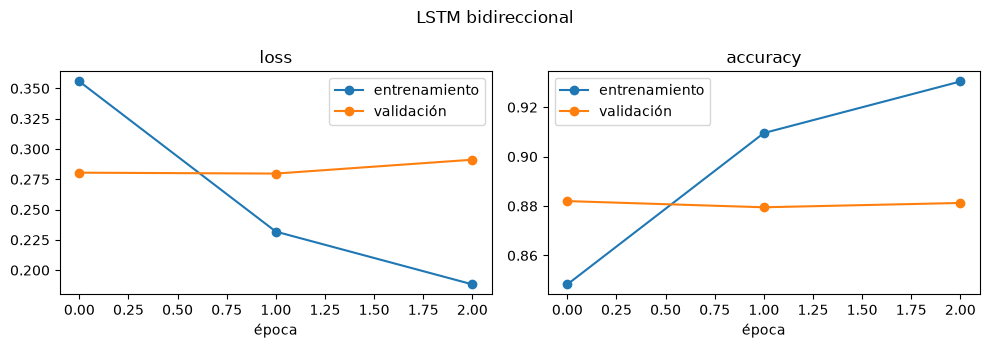

In [9]:
graficar_historial(historiales["LSTM bidireccional"], "LSTM bidireccional")

Algunas observaciones:

- Los modelos con compuertas (LSTM, GRU) superan al promedio de embeddings, porque pueden usar el orden de las palabras. La **SimpleRNN** suele quedar por debajo de ellos: le cuesta aprovechar el contexto lejano y su entrenamiento es más inestable.
- Las diferencias entre LSTM, GRU y la bidireccional son pequeñas en esta tarea, y el costo computacional crece bastante.
- Con reseñas cortas y una tarea en la que unas pocas palabras deciden la clase, la ganancia de los modelos secuenciales sobre una buena bolsa de palabras es moderada. Los modelos secuenciales destacan más en tareas donde la estructura importa: etiquetado de secuencias, traducción y generación.
- Las curvas muestran que el modelo empieza a **sobreajustar** después de pocas épocas (la pérdida de validación deja de bajar mientras la de entrenamiento sigue bajando); la parada temprana se queda con los mejores pesos.

<a id="entienden-las-negaciones"></a>
<h2 style="color: #007ACC;">¿Entienden las negaciones?</h2>

El ejemplo clásico de por qué el orden importa son las **negaciones**. Comparemos el modelo de promedio con la LSTM bidireccional en frases diseñadas para ello:

In [10]:
frases = [
    "El producto es bueno",
    "El producto no es bueno",
    "No está mal",
    "No me gustó nada",
    "No tengo ninguna queja, funciona perfecto",
    "Esperaba que fuera malo, pero me sorprendió para bien",
    "Es bonito pero se rompió a los dos días",
    "Se rompió a los dos días, pero es bonito",
]
X_frases = vectorizador(np.array(frases)).numpy()
pd.DataFrame({
    "frase": frases,
    "P(positiva) promedio": modelos["Promedio"].predict(X_frases, verbose=0).ravel().round(3),
    "P(positiva) BiLSTM": modelos["LSTM bidireccional"].predict(X_frases, verbose=0).ravel().round(3),
})

,frase,P(positiva) promedio,P(positiva) BiLSTM
0,El producto es bueno,0.948,0.744
1,El producto no es bueno,0.074,0.190
2,No está mal,0.000,0.044
3,No me gustó nada,0.001,0.081
4,"No tengo ninguna queja, funciona perfecto",0.999,0.819
5,"Esperaba que fuera malo, pero me sorprendió pa...",0.610,0.781
6,Es bonito pero se rompió a los dos días,0.005,0.039
7,"Se rompió a los dos días, pero es bonito",0.005,0.031


El modelo de promedio asigna la misma información a una palabra sin importar dónde aparezca, así que una negación solo puede "restar" de forma global. Los modelos recurrentes pueden, en principio, modelar el **alcance** de la negación y el orden de las cláusulas (*"X pero Y"*). En la tabla:

- La BiLSTM es más moderada en sus probabilidades y maneja mejor la frase con contraste *"Esperaba que fuera malo, pero me sorprendió para bien"*.
- Ninguno de los dos entiende *"No está mal"*: en las reseñas de entrenamiento, *no* y *mal* aparecen casi siempre en opiniones negativas.
- Cambiar el orden de las cláusulas (*"Es bonito pero se rompió"* frente a *"Se rompió, pero es bonito"*) casi no altera las predicciones: en las reseñas, *se rompió* domina la opinión.

Los modelos recurrentes aprenden estos patrones solo si aparecen con suficiente frecuencia en los datos de entrenamiento.

<a id="generacion-de-texto-caracter-a-caracter"></a>
<h2 style="color: #007ACC;">Generación de texto carácter a carácter</h2>

Un **modelo de lenguaje neuronal** predice el siguiente símbolo a partir de los anteriores, igual que los N-gramas del cuaderno 06, pero con un estado recurrente que resume **todo** el contexto previo. Lo entrenaremos a nivel de **caracteres** con *Don Quijote de la Mancha*:

- El vocabulario es diminuto (letras, signos de puntuación), así que no hay palabras desconocidas.
- El modelo tiene que aprender desde la ortografía hasta la sintaxis.

Cada ejemplo es un fragmento de 100 caracteres; la salida esperada es el mismo fragmento desplazado una posición (*"Don Quijot"* → *"on Quijote"*). La red predice el siguiente carácter **en cada posición** (`return_sequences=True`).

In [11]:
import urllib.request

texto = urllib.request.urlopen("https://www.gutenberg.org/cache/epub/2000/pg2000.txt").read().decode("utf-8")
texto = texto[texto.find("*** START OF"):texto.find("*** END OF")]
texto = texto[texto.find("En un lugar de la Mancha"):]   # empezamos en el capítulo 1
texto = re.sub(r"\s+", " ", texto)

caracteres = sorted(set(texto))
c2i = {c: i for i, c in enumerate(caracteres)}
ids = np.array([c2i[c] for c in texto])
print(f"Caracteres: {len(texto):,} | vocabulario: {len(caracteres)} símbolos")
print(texto[:300])

Caracteres: 2,066,109 | vocabulario: 90 símbolos
En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mucho tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua, rocín flaco y galgo corredor. Una olla de algo más vaca que carnero, salpicón las más noches, duelos y quebrantos los sábados, lantejas los viernes, alg


In [12]:
LONG_SEC, LOTE = 100, 128
n_sec = (len(ids) - 1) // (LONG_SEC + 1)
secuencias = ids[:n_sec * (LONG_SEC + 1)].reshape(n_sec, LONG_SEC + 1)
X_car, Y_car = secuencias[:, :-1], secuencias[:, 1:]

corte = int(0.95 * n_sec)
print(f"Secuencias de entrenamiento: {corte:,} | validación: {n_sec - corte:,}")
print("entrada: ", repr("".join(caracteres[i] for i in X_car[0, :40])))
print("objetivo:", repr("".join(caracteres[i] for i in Y_car[0, :40])))

keras.utils.set_random_seed(SEED)
modelo_car = keras.Sequential([
    keras.Input(shape=(None,), dtype="int64"),
    layers.Embedding(len(caracteres), 64),
    layers.GRU(512, return_sequences=True),
    layers.Dense(len(caracteres)),  # logits: el softmax se aplica en la pérdida
])
modelo_car.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
modelo_car.summary()

Secuencias de entrenamiento: 19,433 | validación: 1,023
entrada:  'En un lugar de la Mancha, de cuyo nombre'
objetivo: 'n un lugar de la Mancha, de cuyo nombre '


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, None, 64)       │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, None, 512)      │       887,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, None, 90)       │        46,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 939,738 (3.58 MB)

 Trainable params: 939,738 (3.58 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
inicio = time.perf_counter()
hist_car = modelo_car.fit(X_car[:corte], Y_car[:corte], validation_data=(X_car[corte:], Y_car[corte:]),
                          epochs=12, batch_size=LOTE, verbose=2)
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s")
print(f"Perplejidad por carácter en validación: {np.exp(hist_car.history['val_loss'][-1]):.2f}")

Epoch 1/12


152/152 - 18s - 121ms/step - loss: 2.4471 - val_loss: 2.0295


Epoch 2/12


152/152 - 18s - 116ms/step - loss: 1.8771 - val_loss: 1.7589


Epoch 3/12


...

Epoch 11/12


152/152 - 17s - 114ms/step - loss: 1.2016 - val_loss: 1.2610


Epoch 12/12


152/152 - 17s - 114ms/step - loss: 1.1838 - val_loss: 1.2529


Entrenado en 209 s
Perplejidad por carácter en validación: 3.50


La **perplejidad por carácter** se interpreta igual que en el cuaderno 06: el modelo está tan indeciso como si eligiera uniformemente entre esa cantidad de caracteres, frente a los 90 símbolos posibles.

Para generar, alimentamos un texto inicial, muestreamos el siguiente carácter de la distribución predicha (con una **temperatura**, como en el cuaderno 06), lo añadimos y repetimos. Para no recalcular todo el prefijo en cada paso, guardamos el estado de la GRU entre llamadas:

In [14]:
# Copia del modelo que procesa un carácter a la vez y devuelve también su estado
entrada = keras.Input(shape=(None,), dtype="int64")
estado_entrada = keras.Input(shape=(512,))
emb = modelo_car.layers[0](entrada)
salida_gru, estado = layers.GRU(512, return_sequences=True, return_state=True)(emb, initial_state=estado_entrada)
logits = modelo_car.layers[2](salida_gru)
generador = keras.Model([entrada, estado_entrada], [logits, estado])
generador.layers[3].set_weights(modelo_car.layers[1].get_weights())  # pesos de la GRU entrenada


def generar(inicio, n=300, temperatura=0.7, rng=None):
    rng = rng or np.random.default_rng(SEED)
    ids_inicio = tf.constant([[c2i[c] for c in inicio]], dtype="int64")
    logits, h = generador([ids_inicio, tf.zeros((1, 512))], training=False)
    resultado = inicio
    for _ in range(n):
        p = tf.nn.softmax(logits[0, -1] / temperatura).numpy().astype("float64")
        siguiente = rng.choice(len(caracteres), p=p / p.sum())
        resultado += caracteres[siguiente]
        logits, h = generador([tf.constant([[siguiente]], dtype="int64"), h], training=False)
    return resultado


for T in [0.3, 0.7, 1.1]:
    print(f"--- temperatura {T} ---")
    print(generar("—Señor —dijo Sancho—, ", temperatura=T), "\n")

--- temperatura 0.3 ---


—Señor —dijo Sancho—, que es menester que se puede ser mejor que no le decía que en la cabeza y a los demás se le había de hacer a su castillo, porque no se ha de ser de la mano de la cabeza y descomunal y en el suelo por los amigos de lo que hacen los demás de los demás con la cabeza y de la cabeza y a los de la cueva d 

--- temperatura 0.7 ---


—Señor —dijo Sancho—, sino una levantar que vuestra merced no le hace mencida. ¿Cargas le consiente que se cuentan en el suelo, porque no se le acababa a la buena propia del Toboso, don Quijote de las más de las razones, entre las honras del campo, que los que dijeren la muerte, de que el caballero se dejó a la buena sue 

--- temperatura 1.1 ---


—Señor —dijo Sancho—, sino yo de todo el otro, como sé llama? Yo, siendo Dulcinea del Toboso escogió mucha condición que yo juro del cargo, porque no es un naver las lejos presentes. — Arespondió Santán—; porque yo se muerto dal maniferos! — Heré —6eplicó la paflica. — Hento, señor —odé: — A Sancho yo en mi deje y rozón, 



Sin conocer ninguna palabra de antemano, el modelo aprendió ortografía, palabras frecuentes, puntuación de los diálogos (*—dijo Sancho—*), el tratamiento de *vuestra merced* y fragmentos del estilo cervantino. Con temperatura baja el texto es más correcto pero repetitivo; con temperatura alta aparecen palabras inventadas.

Como los N-gramas, el modelo **no tiene coherencia global**: el estado de una GRU es un vector de tamaño fijo que no alcanza a guardar el hilo de un párrafo. En el siguiente cuaderno usaremos las RNN para transformar una secuencia en otra (**Seq2Seq**) y veremos que este cuello de botella del vector de tamaño fijo motiva el **mecanismo de atención** (módulo 4).

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.), capítulos 10 y 11. Manning.
- Hochreiter, S. & Schmidhuber, J. (1997). Long Short-Term Memory. *Neural Computation*, 9(8).
- Cho, K. et al. (2014). Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation. *EMNLP*.
- Bengio, Y., Simard, P. & Frasconi, P. (1994). Learning long-term dependencies with gradient descent is difficult. *IEEE Transactions on Neural Networks*, 5(2).
- Karpathy, A. (2015). The Unreasonable Effectiveness of Recurrent Neural Networks. [karpathy.github.io](https://karpathy.github.io/2015/05/21/rnn-effectiveness/)